<div class="alert alert-primary" role="alert">
    <h1 align="center">Fifth Practice: Low-Light Image Enhancement</h1>
    <h3>1. Linear Contrast & Brightness Adjustment</h3>
    <p>Apply <code>cv2.convertScaleAbs</code> with tuned <b>alpha</b> (contrast scaling) and <b>beta</b> (brightness shift) parameters to brighten the image linearly.</p>
    <h3>2. Non-Linear Gamma Correction</h3>
    <p>Construct an 8-bit <b>Look-Up Table (LUT)</b> using $O = 255 \times (I / 255)^\gamma$ across multiple gamma values to non-linearly reveal shadowed details without overexposing highlights.</p>
    <h3>3. Comparative Visualization</h3>
    <p>Render and compare all results side-by-side using <b>Matplotlib subplots</b>, annotating each transformation with its corresponding parameters.</p>
    <hr>
    <p><b>Note:</b> Linear scaling affects all intensities uniformly and often causes saturation/clipping, whereas Gamma Correction with $\gamma < 1$ dynamically brightens dark regions while preserving mid-tones and highlights.</p>
</div>


<div class="alert alert-warning" role="alert" align="center">
    <h4>Marzieh Naseri</h4>
</div>

In [2]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

In [18]:
gamas2=[2,1,0.5,0.3,0.2]
img = cv2.imread("images/Weeki_Wachee_spring_10079u.jpg")
alpha=1.3
beta=40

In [15]:
output_linear = cv2.convertScaleAbs(img, alpha=1.3, beta=40)

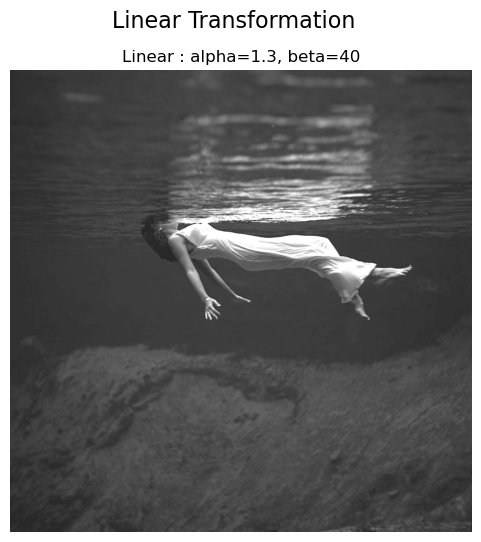

<Figure size 640x480 with 0 Axes>

In [23]:
gamas_output = []

for gama in gamas2:
    lookUpTable = np.empty((1, 256), np.uint8)

    for i in range(256):
        lookUpTable[0, i] = np.clip(pow(i / 255.0, gama) * 255.0,0,255)

    out = cv2.LUT(img, lookUpTable)
    gamas_output.append((gama, out))

#linear
plt.figure(figsize=(6, 6))
plt.suptitle("Linear Transformation", fontsize=16, y=0.98)
plt.imshow(output_linear, cmap='gray')
plt.title(f"Linear : alpha={alpha}, beta={beta}")
plt.axis('off')
plt.show()

plt.tight_layout()
plt.show()



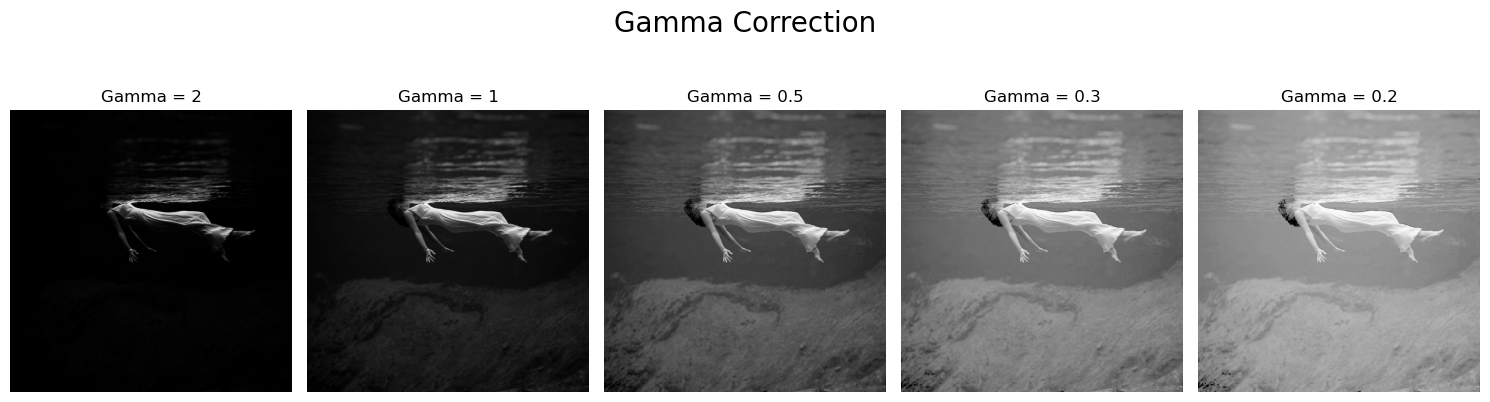

In [27]:
#gamma
plt.figure(figsize=(15, 4))
plt.suptitle("Gamma Correction", fontsize=20, y=1.05)
for idx, (gama, out_img) in enumerate(gamas_output):
    plt.subplot(1, len(gamas2), idx + 1)
    plt.imshow(out_img, cmap='gray')
    plt.title(f"Gamma = {gama}")
    plt.axis('off')

plt.tight_layout()
plt.show()